In [1]:

import os
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

pasta_dados = "../dados"

print("Configurações carregadas!")


Configurações carregadas!


In [2]:

def normalizar(valor):
    if pd.isna(valor):
        return ""

    texto = unicodedata.normalize("NFKD", str(valor))
    texto = texto.encode("ASCII", "ignore").decode("ASCII")

    return re.sub(r"[^A-Z0-9]", "", texto.upper())

print("Função de normalização criada!")


Função de normalização criada!


In [3]:

anos = [2022, 2023, 2024, 2025]

bases = []

for ano in anos:
    caminho = os.path.join(
        pasta_dados,
        f"safephone_{ano}.parquet"
    )

    df = pd.read_parquet(caminho)
    df["ANO_ARQUIVO"] = ano

    bases.append(df)

dados_completos = pd.concat(
    bases,
    ignore_index=True
)

print("Total de registros:", len(dados_completos))
print("\nRegistros por arquivo:")
display(dados_completos["ANO_ARQUIVO"].value_counts().sort_index())


Total de registros: 6253

Registros por arquivo:


ANO_ARQUIVO
2022    2062
2023    1400
2024    1370
2025    1421
Name: count, dtype: int64

In [4]:

colunas_completas = [
    "NOME_DELEGACIA",
    "ANO_BO",
    "NUM_BO",
    "NOME_MUNICIPIO",
    "DATA_OCORRENCIA_BO",
    "HORA_OCORRENCIA",
    "RUBRICA",
    "BAIRRO",
    "DESCR_TIPO_OBJETO",
    "DESCR_SUBTIPO_OBJETO",
    "MARCA_OBJETO",
    "QUANTIDADE_OBJETO"
]

categorias = [
    "Furto (art. 155)",
    "Furto qualificado (art. 155, §4o.)",
    "Roubo (art. 157)"
]

print("Colunas e categorias definidas!")


Colunas e categorias definidas!


In [5]:

import numpy as np

quantidades = {
    2022: 442730,
    2023: 490154,
    2024: 412527,
    2025: 383635
}

for ano, total_linhas in quantidades.items():
    print(f"\nProcessando {ano}...")

    arquivo = os.path.join(
        pasta_dados,
        f"CelularesSubtraidos_{ano}.xlsx"
    )

    rng = np.random.default_rng(42 + ano)

    linhas = set(rng.choice(
        np.arange(1, total_linhas + 1),
        size=3000,
        replace=False
    ))

    amostra = pd.read_excel(
        arquivo,
        sheet_name=f"CELULAR_{ano}",
        usecols=lambda c: c in colunas_completas,
        skiprows=lambda i: i > 0 and i not in linhas,
        dtype=str,
        engine="calamine"
    )

    # Filtrar São Paulo
    amostra = amostra[
        amostra["NOME_MUNICIPIO"].apply(normalizar)
        .isin(["SPAULO", "SAOPAULO"])
    ].copy()

    # Filtrar celulares
    amostra = amostra[
        amostra["DESCR_SUBTIPO_OBJETO"].apply(normalizar)
        .isin(["TELEFONECELULAR", "TELEFONECELULARRADIO"])
    ]

    # Filtrar furtos e roubos
    amostra = amostra[
        amostra["RUBRICA"].isin(categorias)
    ].copy()

    amostra["ANO_ARQUIVO"] = ano

    # Salvar
    destino = os.path.join(
        pasta_dados,
        f"safephone_{ano}.parquet"
    )

    amostra.to_parquet(destino, index=False)

    print("Registros válidos:", len(amostra))
    print("Arquivo salvo:", destino)

    print("Distribuição mensal:")
    display(
        pd.to_datetime(
            amostra["DATA_OCORRENCIA_BO"],
            errors="coerce"
        ).dt.month.value_counts().sort_index()
    )



Processando 2022...
Registros válidos: 2062
Arquivo salvo: ../dados\safephone_2022.parquet
Distribuição mensal:


DATA_OCORRENCIA_BO
1     167
2     156
3     180
4     193
5     192
6     164
7     147
8     169
9     189
10    164
11    157
12    184
Name: count, dtype: int64


Processando 2023...
Registros válidos: 1400
Arquivo salvo: ../dados\safephone_2023.parquet
Distribuição mensal:


DATA_OCORRENCIA_BO
1     114
2     125
3     134
4     104
5     121
6     131
7     106
8     107
9      95
10    117
11    122
12    124
Name: count, dtype: int64


Processando 2024...
Registros válidos: 1370
Arquivo salvo: ../dados\safephone_2024.parquet
Distribuição mensal:


DATA_OCORRENCIA_BO
1     104
2     123
3     118
4     118
5     107
6     129
7     110
8     111
9     102
10    128
11     96
12    124
Name: count, dtype: int64


Processando 2025...
Registros válidos: 1421
Arquivo salvo: ../dados\safephone_2025.parquet
Distribuição mensal:


DATA_OCORRENCIA_BO
1     108
2     104
3     130
4     124
5     123
6     129
7     112
8     120
9     123
10    111
11    120
12    117
Name: count, dtype: int64

In [6]:

# Remover datas inválidas
dados_completos["DATA_OCORRENCIA_BO"] = pd.to_datetime(
    dados_completos["DATA_OCORRENCIA_BO"],
    errors="coerce"
)

# Manter somente ocorrências entre 2020 e 2025
dados_limpos = dados_completos[
    dados_completos["DATA_OCORRENCIA_BO"].dt.year.between(2020, 2025)
].copy()

# Padronizar bairros
dados_limpos["BAIRRO"] = (
    dados_limpos["BAIRRO"].apply(normalizar)
)

dados_limpos["BAIRRO"] = (
    dados_limpos["BAIRRO"].replace("", "NAO INFORMADO")
)

# Recriar identificador dos boletins
dados_limpos["ID_BO"] = (
    dados_limpos[
        ["NOME_DELEGACIA", "ANO_BO", "NUM_BO"]
    ]
    .fillna("")
    .astype(str)
    .agg("_".join, axis=1)
)

# Uma linha por ocorrência
dados_ocorrencias = dados_limpos.drop_duplicates(
    subset=["ID_BO"]
).copy()

dados_ocorrencias["ANO"] = (
    dados_ocorrencias["DATA_OCORRENCIA_BO"].dt.year
)

dados_ocorrencias["MES"] = (
    dados_ocorrencias["DATA_OCORRENCIA_BO"].dt.month
)

print("Registros após limpeza:", len(dados_limpos))
print("Ocorrências únicas:", len(dados_ocorrencias))

print("\nDistribuição por ano:")
display(
    dados_ocorrencias["ANO"]
    .value_counts()
    .sort_index()
    .to_frame("Ocorrências")
)

dados_ocorrencias.to_parquet(
    os.path.join(pasta_dados, "safephone_base_limpa.parquet"),
    index=False
)

print("Base limpa salva com sucesso!")

Registros após limpeza: 6246
Ocorrências únicas: 6220

Distribuição por ano:


,Ocorrências
ANO,
2020,4
2021,29
2022,2033
2023,1396
2024,1359
2025,1399


Base limpa salva com sucesso!


In [7]:

# Separar treinamento e teste por ano
dados_treino = dados_ocorrencias[
    dados_ocorrencias["ANO"].between(2022, 2024)
].copy()

dados_teste = dados_ocorrencias[
    dados_ocorrencias["ANO"] == 2025
].copy()

# Selecionar os 20 bairros usando somente treinamento
top_bairros = (
    dados_treino["BAIRRO"]
    .value_counts()
    .head(20)
    .index
)

# Aplicar os mesmos bairros nos dois conjuntos
dados_treino = dados_treino[
    dados_treino["BAIRRO"].isin(top_bairros)
].copy()

dados_teste = dados_teste[
    dados_teste["BAIRRO"].isin(top_bairros)
].copy()

# Agregar por bairro, ano e mês
def agregar_dados(df):
    return (
        df.groupby(["BAIRRO", "ANO", "MES"])
        .agg(
            TOTAL_OCORRENCIAS=("ID_BO", "nunique")
        )
        .reset_index()
    )

base_treino = agregar_dados(dados_treino)
base_teste = agregar_dados(dados_teste)

print("Bairros:", len(top_bairros))
print("Grupos de treinamento:", len(base_treino))
print("Grupos de teste:", len(base_teste))

print("\nTreinamento por ano:")
display(base_treino.groupby("ANO").size())

print("\nTeste por ano:")
display(base_teste.groupby("ANO").size())


Bairros: 20
Grupos de treinamento: 627
Grupos de teste: 216

Treinamento por ano:


ANO
2022    215
2023    205
2024    207
dtype: int64


Teste por ano:


ANO
2025    216
dtype: int64

In [8]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Variáveis de entrada
X_train = base_treino[["BAIRRO", "ANO", "MES"]]
y_train = base_treino["TOTAL_OCORRENCIAS"]

X_test = base_teste[["BAIRRO", "ANO", "MES"]]
y_test = base_teste["TOTAL_OCORRENCIAS"]

# Transformar bairro em variável numérica
preprocessador = ColumnTransformer(
    transformers=[
        ("bairro", OneHotEncoder(handle_unknown="ignore"), ["BAIRRO"])
    ],
    remainder="passthrough"
)

# Pipeline do modelo
pipeline = Pipeline([
    ("preprocessador", preprocessador),
    ("modelo", RandomForestRegressor(random_state=42))
])

print("Variáveis de treinamento:", X_train.shape)
print("Variáveis de teste:", X_test.shape)
print("Preparação concluída!")


Variáveis de treinamento: (627, 3)
Variáveis de teste: (216, 3)
Preparação concluída!


In [9]:

# Grade de hiperparâmetros: 12 combinações
parametros = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [None, 10],
    "modelo__min_samples_split": [2, 5, 10]
}

# Validação cruzada: somente dados de treinamento
cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Busca das melhores configurações
busca = GridSearchCV(
    estimator=pipeline,
    param_grid=parametros,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

# Treinar e comparar
busca.fit(X_train, y_train)

print("\nMELHORES HIPERPARÂMETROS:")
print(busca.best_params_)

print("\nMELHOR MAE NA VALIDAÇÃO CRUZADA:")
print(-busca.best_score_)

print("\nTOTAL DE EXPERIMENTOS:")
print(len(busca.cv_results_["params"]))


Fitting 3 folds for each of 12 candidates, totalling 36 fits

MELHORES HIPERPARÂMETROS:
{'modelo__max_depth': 10, 'modelo__min_samples_split': 10, 'modelo__n_estimators': 200}

MELHOR MAE NA VALIDAÇÃO CRUZADA:
1.231506764687688

TOTAL DE EXPERIMENTOS:
12


In [10]:

# Recuperar o melhor modelo
modelo_final = busca.best_estimator_

# Fazer previsões
previsoes_treino = modelo_final.predict(X_train)
previsoes_teste = modelo_final.predict(X_test)

# Função de avaliação
def avaliar_modelo(real, previsto):
    return {
        "MAE": mean_absolute_error(real, previsto),
        "RMSE": np.sqrt(mean_squared_error(real, previsto)),
        "R2": r2_score(real, previsto)
    }

# Avaliar os dois conjuntos
resultado_treino = avaliar_modelo(
    y_train, previsoes_treino
)

resultado_teste = avaliar_modelo(
    y_test, previsoes_teste
)

# Comparação
comparacao = pd.DataFrame(
    [resultado_treino, resultado_teste],
    index=["Treinamento", "Teste (2025)"]
)

display(comparacao.round(4))


,MAE,RMSE,R2
Treinamento,1.0555,1.3428,0.4207
Teste (2025),1.0746,1.4047,0.1080


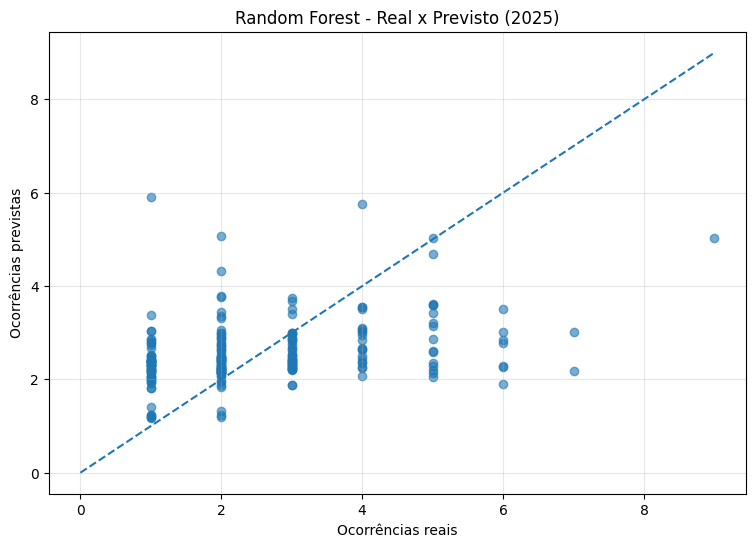

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    previsoes_teste,
    alpha=0.6
)

limite = max(y_test.max(), previsoes_teste.max())

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--"
)

plt.xlabel("Ocorrências reais")
plt.ylabel("Ocorrências previstas")
plt.title("Random Forest - Real x Previsto (2025)")
plt.grid(alpha=0.3)

plt.show()


In [12]:

from sklearn.dummy import DummyRegressor

# Modelo de referência
modelo_base = DummyRegressor(strategy="mean")
modelo_base.fit(X_train[["MES"]], y_train)

# Previsões
previsoes_base = modelo_base.predict(X_test[["MES"]])

# Avaliação
resultado_base = {
    "MAE": mean_absolute_error(y_test, previsoes_base),
    "RMSE": np.sqrt(mean_squared_error(y_test, previsoes_base)),
    "R2": r2_score(y_test, previsoes_base)
}

# Comparação dos modelos
comparacao_modelos = pd.DataFrame(
    [
        resultado_base,
        resultado_teste
    ],
    index=["Modelo básico", "Random Forest"]
)

display(comparacao_modelos.round(4))


,MAE,RMSE,R2
Modelo básico,1.2326,1.5047,-0.0235
Random Forest,1.0746,1.4047,0.1080


,Variavel,Importancia
21,MES,0.296471
20,ANO,0.268447
14,BAIRRO_REPUBLICA,0.105593
5,BAIRRO_CENTRO,0.078985
6,BAIRRO_CONSOLACAO,0.055406
13,BAIRRO_PINHEIROS,0.033136
3,BAIRRO_BRAS,0.029250
17,BAIRRO_SE,0.018755
2,BAIRRO_BOMRETIRO,0.016778
1,BAIRRO_BELAVISTA,0.016159


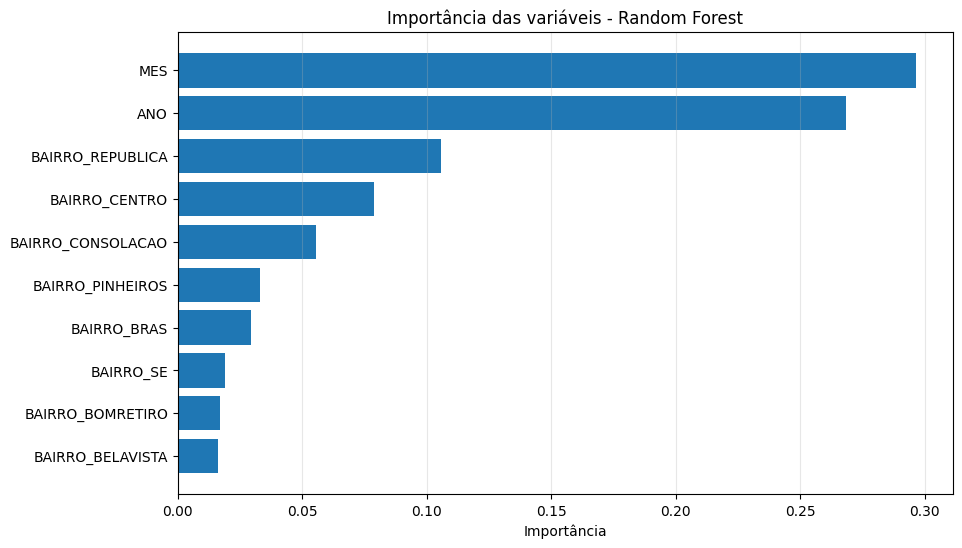

In [13]:

# Recuperar o modelo Random Forest treinado
rf = modelo_final.named_steps["modelo"]
encoder = modelo_final.named_steps["preprocessador"]

# Obter nomes das variáveis após transformação
nomes_bairros = (
    encoder.named_transformers_["bairro"]
    .get_feature_names_out(["BAIRRO"])
)

nomes_variaveis = list(nomes_bairros) + ["ANO", "MES"]

# Importância das variáveis
importancias = pd.DataFrame({
    "Variavel": nomes_variaveis,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

display(importancias.head(15))

# Gráfico
plt.figure(figsize=(10, 6))

top = importancias.head(10).sort_values("Importancia")

plt.barh(top["Variavel"], top["Importancia"])
plt.xlabel("Importância")
plt.title("Importância das variáveis - Random Forest")
plt.grid(axis="x", alpha=0.3)

plt.show()


In [14]:

# Modelo alternativo sem a variável ANO
X_train_v2 = base_treino[["BAIRRO", "MES"]]
X_test_v2 = base_teste[["BAIRRO", "MES"]]

pipeline_v2 = Pipeline([
    ("preprocessador", ColumnTransformer([
        ("bairro", OneHotEncoder(handle_unknown="ignore"), ["BAIRRO"])
    ], remainder="passthrough")),
    ("modelo", RandomForestRegressor(random_state=42))
])

busca_v2 = GridSearchCV(
    pipeline_v2,
    parametros,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

busca_v2.fit(X_train_v2, y_train)

previsoes_v2 = busca_v2.best_estimator_.predict(X_test_v2)

resultado_v2 = avaliar_modelo(y_test, previsoes_v2)

print("Melhores parâmetros:", busca_v2.best_params_)
print("\nResultado sem ANO:")
print(resultado_v2)


Melhores parâmetros: {'modelo__max_depth': 10, 'modelo__min_samples_split': 10, 'modelo__n_estimators': 200}

Resultado sem ANO:
{'MAE': 1.1929610194379303, 'RMSE': np.float64(1.5301679636212697), 'R2': -0.05841386116956748}


In [15]:

# Salvar o modelo final
caminho_modelo = os.path.join(
    pasta_dados,
    "safephone_modelo.pkl"
)

joblib.dump(modelo_final, caminho_modelo)

print("Modelo salvo em:", caminho_modelo)

# Comparação final dos três modelos
comparacao_final = pd.DataFrame(
    [
        resultado_base,
        resultado_teste,
        resultado_v2
    ],
    index=[
        "Modelo básico",
        "Random Forest com ANO",
        "Random Forest sem ANO"
    ]
)

display(comparacao_final.round(4))


Modelo salvo em: ../dados\safephone_modelo.pkl


,MAE,RMSE,R2
Modelo básico,1.2326,1.5047,-0.0235
Random Forest com ANO,1.0746,1.4047,0.1080
Random Forest sem ANO,1.1930,1.5302,-0.0584


In [16]:
import os
import pandas as pd

caminho = os.path.join(
    pasta_dados,
    "safephone_base_limpa.parquet"
)

base_final = pd.read_parquet(caminho)

print("REGISTROS APÓS LIMPEZA:", len(base_final))

if "ID_BO" in base_final.columns:
    print("BOLETINS ÚNICOS:", base_final["ID_BO"].nunique())

print("\nREGISTROS POR ANO:")
display(base_final["ANO"].value_counts().sort_index())

print("\nBAIRROS REPRESENTADOS:", base_final["BAIRRO"].nunique())

REGISTROS APÓS LIMPEZA: 6220
BOLETINS ÚNICOS: 6220

REGISTROS POR ANO:


ANO
2020       4
2021      29
2022    2033
2023    1396
2024    1359
2025    1399
Name: count, dtype: int64


BAIRROS REPRESENTADOS: 933
